# Gene expression programming from scratch

`ed_symbolic_regression.ipynb` evolves expression *trees* directly (tree-based genetic programming). **Gene expression
programming** (GEP; Ferreira, 2001) evolves fixed-length *strings* instead and *expresses* each string as a tree, much as
a gene is a linear sequence that is expressed as a folded protein. This separation of genotype and phenotype has two
consequences that tree GP lacks:

* **every chromosome is a valid expression**, whatever the genetic operators do to it, because of a simple rule on
  the length of its tail;
* part of every chromosome is **non-coding**, so many mutations are neutral, which lets variation accumulate without
  breaking good solutions.

Sections: (1) the chromosome, the head/tail rule and the Karva decoding; (2) the genetic operators; (3) GEP on the
wake decay law and the vessel drag correction of the tree-GP notebook, with the same data, linear scaling and noise;
(4) why validity by construction matters.

The prose narrates the **default** run. Change the values below and *Run All*; checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
HEAD = 7                         # head length h; the tail length follows from the head/tail rule
POP_N, GENS = 200, 50            # population and generations
N_SEEDS = 10                     # seeds for the success-rate check
WAKE_NOISE, DRAG_NOISE = 0.04, 0.15   # the data of ed_symbolic_regression.ipynb
EXAMPLE_SEED = 1                 # the wake run whose chromosome is drawn in the chapter and slides
# --------------------------------------------------------------------------
DEFAULTS = dict(HEAD=7, POP_N=200, GENS=50, N_SEEDS=10, WAKE_NOISE=0.04, DRAG_NOISE=0.15, EXAMPLE_SEED=1)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

## 1. Chromosome, head/tail rule, Karva decoding

A GEP gene is a string of length $h+t$. The **head** (first $h$ symbols) may hold functions or terminals; the **tail**
holds terminals only. If the largest function arity is $n$, a head made entirely of $n$-ary functions needs
$h(n-1)+1$ leaves, so choosing
$$t=h(n-1)+1$$
guarantees that the tail always supplies enough terminals: no string can ever be an invalid expression. The string is
read as a **K-expression** (Karva notation): the first symbol is the root, and the following symbols fill the tree
level by level, left to right, each node taking as many children as its arity. Reading stops when every branch ends
in a terminal; the symbols read form the *open reading frame* (ORF), and the rest of the gene is non-coding.

Symbols here: functions $\{+,-,\times,\div,\mathrm{Q}=\sqrt{|\cdot|},\mathrm{A}=|\cdot|\}$ and terminals
$\{x,1\}$. With linear scaling (as in the tree-GP notebook) every outer constant comes free, so the terminal $1$ is
the only constant needed.

In [2]:
import sys, os, random, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted; set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
ARITY={'+':2,'-':2,'*':2,'/':2,'Q':1,'A':1}
FN={'+':np.add,'-':np.subtract,'*':np.multiply,'/':lambda a,b: np.where(np.abs(b)>1e-6,a/np.where(np.abs(b)>1e-6,b,1),1.0),
    'Q':lambda a: np.sqrt(np.abs(a)),'A':np.abs}
def decode(chrom):
    # Karva: breadth-first; returns list of nodes (sym, children idx) for the expressed region
    nodes=[[chrom[0],[]]]; i=1; level=[0]
    while level:
        nxt=[]
        for k in level:
            for _ in range(ARITY.get(nodes[k][0],0)):
                nodes.append([chrom[i],[]]); nodes[k][1].append(len(nodes)-1); nxt.append(len(nodes)-1); i+=1
        level=nxt
    return nodes   # len(nodes) = coding length (ORF)
def ev(nodes,x,k=0):
    s,ch=nodes[k]
    if s=='x': return x
    if s=='1': return np.ones_like(x)
    return FN[s](*[ev(nodes,x,c) for c in ch])
def to_str(nodes,k=0):
    s,ch=nodes[k]
    if not ch: return s
    if len(ch)==1: return {'Q':'sqrt','A':'abs'}[s]+f'({to_str(nodes,ch[0])})'
    return f'({to_str(nodes,ch[0])} {s} {to_str(nodes,ch[1])})'
def scaled(g,y):
    if not np.all(np.isfinite(g)) : return np.inf,0,1
    vg=g.var()
    if vg<1e-12: return float(y.var()),float(y.mean()),0.0
    b=np.mean((g-g.mean())*(y-y.mean()))/vg; a=y.mean()-b*g.mean(); return float(np.mean((a+b*g-y)**2)),a,b
class GEP:
    def __init__(s,funcs,terms,h=HEAD,seed=0):
        s.F=funcs; s.T=terms; s.h=h; s.t=h*(max(ARITY[f] for f in funcs)-1)+1; s.L=s.h+s.t; s.r=random.Random(seed)
    def rand(s): return [s.r.choice(s.F+s.T) for _ in range(s.h)]+[s.r.choice(s.T) for _ in range(s.t)]
    def mutate(s,c,p=0.044):
        c=c[:]
        for i in range(s.L):
            if s.r.random()<p: c[i]=s.r.choice(s.F+s.T) if i<s.h else s.r.choice(s.T)
        return c
    def is_transpose(s,c):   # insert a short sequence into the head (not at root), head length kept
        c=c[:]; ln=s.r.choice([1,2,3]); st=s.r.randrange(s.L-ln+1); seq=c[st:st+ln]; tgt=s.r.randrange(1,s.h)
        head=c[:tgt]+seq+c[tgt:s.h]; c[:s.h]=head[:s.h]; return c
    def ris_transpose(s,c):  # a sequence starting with a function moves to the root
        c=c[:]; fpos=[i for i in range(s.h) if c[i] in s.F]
        if not fpos: return c
        st=s.r.choice(fpos); ln=s.r.choice([1,2,3]); seq=c[st:st+ln]; head=seq+c[:s.h]; c[:s.h]=head[:s.h]; return c
    def onepoint(s,a,b):
        k=s.r.randrange(1,s.L); return a[:k]+b[k:], b[:k]+a[k:]
    def twopoint(s,a,b):
        i,j=sorted(s.r.sample(range(1,s.L),2)); return a[:i]+b[i:j]+a[j:], b[:i]+a[i:j]+b[j:]
    def run(s,x,y,pop_n=POP_N,gens=GENS,gamma=1e-3):
        vy=y.var()
        def fit(c):
            nd=decode(c); m,_,_=scaled(ev(nd,x),y); return m/vy+gamma*len(nd), nd
        pop=[s.rand() for _ in range(pop_n)]; best=None; hist=[]
        for g in range(gens):
            sc=[fit(c) for c in pop]; order=np.argsort([v for v,_ in sc]); pop=[pop[i] for i in order]; sc=[sc[i] for i in order]
            if best is None or sc[0][0]<best[0]: best=(sc[0][0],pop[0],g)
            hist.append((sc[0][0], float(np.mean([len(n) for _,n in sc]))))
            new=[pop[0]]
            while len(new)<pop_n:
                a=pop[min(s.r.sample(range(pop_n),3))]; b=pop[min(s.r.sample(range(pop_n),3))]
                if s.r.random()<0.3: a,b=s.onepoint(a,b)
                if s.r.random()<0.3: a,b=s.twopoint(a,b)
                for c in (a,b):
                    c=s.mutate(c)
                    if s.r.random()<0.1: c=s.is_transpose(c)
                    if s.r.random()<0.1: c=s.ris_transpose(c)
                    new.append(c)
            pop=new[:pop_n]
        return best,hist

# a worked decoding: the chromosome the chapter draws (found by the wake run below, seed EXAMPLE_SEED)
demo = list('/1QxQx+1x111x11')
nodes = decode(demo)
print('gene      :', ''.join(demo[:HEAD]), '|', ''.join(demo[HEAD:]), f'  (head {HEAD}, tail {HEAD*(2-1)+1})')
print('ORF       :', ''.join(demo[:len(nodes)]), f'({len(nodes)} of {len(demo)} symbols coding)')
print('expression:', to_str(nodes))

gene      : /1QxQx+ | 1x111x11   (head 7, tail 8)
ORF       : /1Qx (4 of 15 symbols coding)
expression: (1 / sqrt(x))


## 2. Genetic operators

All operators act on the string, and every result is again a valid gene, because they keep the tail terminal-only and
the lengths fixed:

* **mutation**: any head position may become any symbol, any tail position any terminal (rate $0.044$ per symbol);
* **IS transposition**: a short segment is copied into the head at a non-root position, pushing the rest of the
  head to the right (the overflow is discarded);
* **RIS transposition**: a segment that *starts with a function* is copied to the root;
* **one- and two-point recombination** between two parents.

The cell below shows the most important property: a mutation in the non-coding region changes nothing, a mutation in
the ORF changes the expression, and even a mutation that turns a terminal into a function at the root of a subtree
still yields a valid tree, because the tail absorbs the extra arguments. Without the head/tail rule a random string
often cannot be read to the end of every branch.

In [3]:
def show(c, label):
    nd = decode(c); print(f'{label:34s} {"".join(c[:HEAD])}|{"".join(c[HEAD:])}  ORF {len(nd):2d}  ->  {to_str(nd)}')
show(demo, 'parent')
m1 = demo[:]; m1[9] = 'x';  show(m1, 'mutation at 9 (non-coding)')
m2 = demo[:]; m2[1] = 'x';  show(m2, 'mutation at 1 (coding: 1 -> x)')
m3 = demo[:]; m3[1] = '*';  show(m3, 'mutation at 1 (terminal -> function)')
def orf_length(c):
    # length of the breadth-first reading, or None if the string runs out before every branch ends
    need, k = 1, 0
    while need > 0:
        if k >= len(c): return None
        need += ARITY.get(c[k], 0) - 1; k += 1
    return k
rng_valid = random.Random(0); n_try = 10000
strings = [[rng_valid.choice(list('+-*/Qx1')) for _ in range(2*HEAD + 1)] for _ in range(n_try)]
frac = np.mean([orf_length(c) is not None for c in strings])
print(f'random strings of length {2*HEAD + 1} over the same symbols, no head/tail rule: {frac*100:.1f} % decode to a '
      f'complete expression; with the rule: 100 % by construction')


parent                             /1QxQx+|1x111x11  ORF  4  ->  (1 / sqrt(x))
mutation at 9 (non-coding)         /1QxQx+|1xx11x11  ORF  4  ->  (1 / sqrt(x))
mutation at 1 (coding: 1 -> x)     /xQxQx+|1x111x11  ORF  4  ->  (x / sqrt(x))
mutation at 1 (terminal -> function) /*QxQx+|1x111x11  ORF  9  ->  ((x * sqrt((1 + x))) / sqrt(x))
random strings of length 15 over the same symbols, no head/tail rule: 47.6 % decode to a complete expression; with the rule: 100 % by construction


## 3. GEP on the course benchmarks

The data of `ed_symbolic_regression.ipynb`: the wake centreline deficit $1.128\,x^{-1/2}$ with $4\%$ multiplicative
noise (functions $\{+,-,\times,\div,\mathrm{Q}\}$), and the learned vessel drag correction $-3\,u|u|$ with additive noise
(functions $\{+,-,\times,\div,\mathrm{A}\}$). Fitness: linearly scaled NMSE plus $10^{-3}$ per coding symbol;
tournaments of three; one elite.

In [4]:
rs = np.random.default_rng(0)
xw = np.linspace(1, 8, 60); amp = 1/np.sqrt(4*np.pi*0.0625); yw = amp/np.sqrt(xw)*(1 + WAKE_NOISE*rs.standard_normal(60))
ud = np.linspace(-0.8, 3.9, 80); yd = -3*np.abs(ud)*ud + DRAG_NOISE*rs.standard_normal(80)
problems = {'wake': (xw, yw, ['+', '-', '*', '/', 'Q'], 1.05*np.mean((amp/np.sqrt(xw) - yw)**2)/yw.var()),
            'drag': (ud, yd, ['+', '-', '*', '/', 'A'], 1.5e-4)}
runs = {}
for name, (x, y, F, tgt) in problems.items():
    out = []
    for sd in range(N_SEEDS):
        t0 = time.perf_counter(); best, hist = GEP(F, ['x', '1'], seed=sd).run(x, y); dtime = time.perf_counter() - t0
        nd = decode(best[1]); m, a, b = scaled(ev(nd, x), y)
        out.append(dict(seed=sd, chrom=''.join(best[1]), orf=len(nd), expr=to_str(nd), a=a, b=b, nmse=m/y.var(),
                        gen=best[2], ok=m/y.var() <= tgt, time=dtime, hist=hist))
    runs[name] = out
    print(f'{name}: found on {sum(r["ok"] for r in out)}/{N_SEEDS} seeds; first generation reaching the best: '
          f'median {int(np.median([r["gen"] for r in out]))}; {np.mean([r["time"] for r in out]):.2f} s per run')
    for r in out[:3]:
        print(f'   seed {r["seed"]}: {r["chrom"][:HEAD]}|{r["chrom"][HEAD:]}  ORF {r["orf"]}  {r["a"]:+.3f} {r["b"]:+.3f} * {r["expr"]}'
              f'   NMSE {r["nmse"]:.5f}')
ex = runs['wake'][EXAMPLE_SEED]
print('example chromosome (drawn in the chapter):', ex['chrom'], '->', ex['expr'])
if AT_DEFAULTS:
    assert all(r['ok'] for r in runs['wake'] + runs['drag']) and ex['chrom'] == ''.join(demo)

wake: found on 10/10 seeds; first generation reaching the best: median 3; 0.21 s per run
   seed 0: Q/1xQ+-|x11xxxx1  ORF 4  +0.007 +1.117 * sqrt((1 / x))   NMSE 0.01302
   seed 1: /1QxQx+|1x111x11  ORF 4  +0.007 +1.117 * (1 / sqrt(x))   NMSE 0.01302
   seed 2: /1Qxx1/|1111x1x1  ORF 4  +0.007 +1.117 * (1 / sqrt(x))   NMSE 0.01302


drag: found on 10/10 seeds; first generation reaching the best: median 3; 0.18 s per run
   seed 0: *Axx+xx|1111xxxx  ORF 4  +0.009 -3.000 * (abs(x) * x)   NMSE 0.00012
   seed 1: *Axx+1A|xx11xxxx  ORF 4  +0.009 -3.000 * (abs(x) * x)   NMSE 0.00012
   seed 2: *xAxx11|111x11x1  ORF 4  +0.009 -3.000 * (x * abs(x))   NMSE 0.00012
example chromosome (drawn in the chapter): /1QxQx+1x111x11 -> (1 / sqrt(x))


Both laws are found on every seed, and within a handful of generations: the knee expressions $1.117/\sqrt{x}$ and
$-3.000\,x|x|$ of the tree-GP notebook, now as four coding symbols in a fifteen-symbol gene. These two problems are
easy for any well-engineered search (with linear scaling, tree GP also succeeded on every seed), so the comparison
that matters is not speed but **robustness of representation**: GEP never spends evaluations on invalid or bloated
individuals, because the gene length caps the tree size and the head/tail rule guarantees validity.

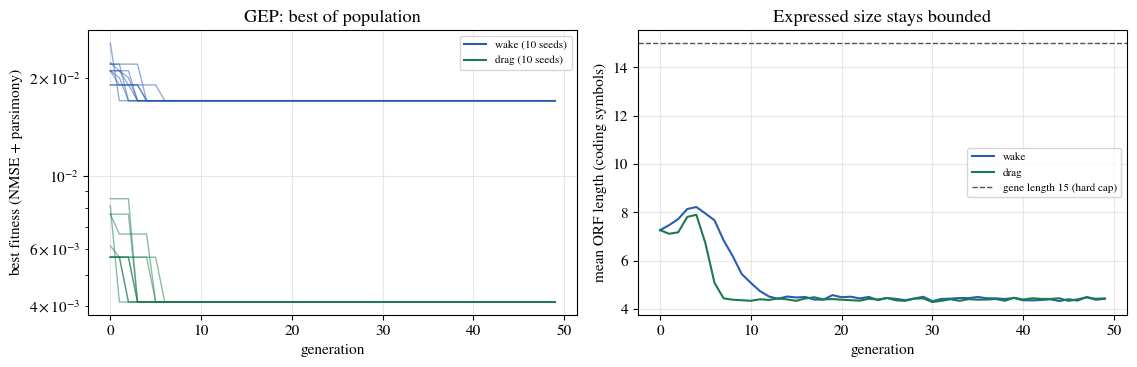

In [5]:
def plot_gep():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
    for name, col in [('wake', 'C0'), ('drag', 'C2')]:
        for r in runs[name]:
            ax[0].semilogy([h[0] for h in r['hist']], color=col, alpha=0.5, lw=1)
        ax[0].plot([], [], color=col, label=f'{name} ({N_SEEDS} seeds)')
        ax[1].plot(np.median([[h[1] for h in r['hist']] for r in runs[name]], 0), color=col, label=name)
    ax[0].set(xlabel='generation', ylabel='best fitness (NMSE + parsimony)', title='GEP: best of population')
    ax[0].legend(fontsize=8)
    ax[1].axhline(2*HEAD + 1, color=muted(), ls='--', lw=1, label=f'gene length {2*HEAD + 1} (hard cap)')
    ax[1].set(xlabel='generation', ylabel='mean ORF length (coding symbols)', title='Expressed size stays bounded')
    ax[1].legend(fontsize=8); plt.tight_layout()

save_dual(plot_gep, 'ed_gep_runs', FIG)
plt.show()

## 4. Takeaways

GEP keeps a fixed-length linear genome and expresses it as a tree. The head/tail rule $t=h(n-1)+1$ makes every gene a
valid expression, so the genetic operators can be as crude as string edits; the non-coding region makes many mutations
neutral; and the gene length caps the expressed size, which is a built-in remedy for the bloat that tree GP needs a
parsimony penalty to control. The price is that the maximum expression size must be chosen in advance (through $h$),
and that a small change in the head can rearrange the whole tree, because the Karva reading is breadth-first. Production
GEP adds multigenic chromosomes linked by a fixed function and dedicated random-constant domains.